In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
import scipy.sparse as sp
import anndata as ad
import gseapy as gp
from copy import deepcopy
import scanpy.external as sce
import pickle

# sc.logging.print_version()
sc.settings.verbosity = 3
sc.set_figure_params(figsize=(5,5))

import sys
from pathlib import Path

_start = Path.cwd().resolve()
_repo_root = next((p for p in [_start, *_start.parents] if (p / "chronopack").exists()), _start)
if str(_repo_root) not in sys.path:
    sys.path.insert(0, str(_repo_root))

from chronopack.tradeseq import (
    ComputeSmoothCorrelations,
    TemporalPseudobulkFromAnnData,
    WriteTradeSeqInputsFromAnnData,
    load_negative_control_logcpm,
    smooth_series,
)
from chronopack.preprocessing import filter_technical_genes


In [2]:
adata_hvg = sc.read_h5ad('../output/adata_hvg.1e4-variant.chk1.h5ad')
adata = sc.read_h5ad('../output/adata_full.1e4-variant.chk1.h5ad')

# Compute CPM & logCPM matrices for negative bulk control

In [4]:
mtx_agg, cpm_ref, logcpm_ref = load_negative_control_logcpm('../../thp1-k562-lps.hg38.rep/intmd/k562_neg-ctrl_mtx-agg.pkl')


# Compute pseudobulk CPM & logCPM matrices for LPS+THP1 experiment

In [6]:
cpm, logcpm = TemporalPseudobulkFromAnnData(adata)


# Prioritize genes by variation over time

In [9]:
def RenameClusters(x):
    if (x == '0'): return 'K562_Immune'
    if (x == '1'): return 'K562_Erythroid'

adata.obs['cell_type'] = adata.obs['traj_clusters'].apply(RenameClusters)

# New approach

# END

In [21]:
shared_genes = list(set(adata.var.index) & set(logcpm_ref.columns))

cpm_ref = cpm_ref.loc[:, shared_genes]
logcpm_ref = logcpm_ref.loc[:, shared_genes]

cpm = cpm.loc[:, shared_genes]
logcpm = logcpm.loc[:, shared_genes]

adata.shape

(6857, 20036)

# Compute correlations

                 pearson_r_smooth  pearson_r_residual  pearson_r_diff  \
gene                                                                    
PAK5                     1.000000            1.000000        1.000000   
MAP6                     1.000000            1.000000        1.000000   
ENSG00000279881          1.000000            1.000000        1.000000   
DDX25                    1.000000            1.000000        1.000000   
LINC02029                1.000000            1.000000        1.000000   
LINC01206                1.000000            1.000000        1.000000   
ENSG00000305226          0.628105            0.998625        0.930697   
MT-RNR1                  0.984063            0.998284        0.994238   
ENSG00000288845          0.965318            0.985284        0.996473   
HNRNPA1P23               0.884626            0.990989        0.978912   
ENSG00000300574          0.839768            0.982767        0.986981   
MT-ND4                   0.825428            0.9866

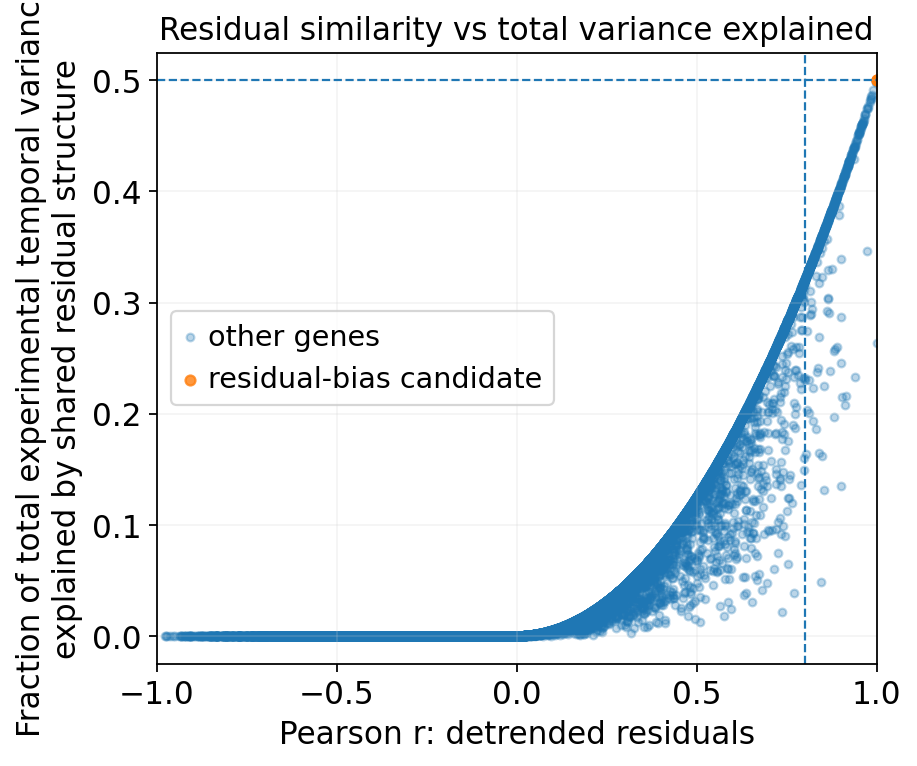

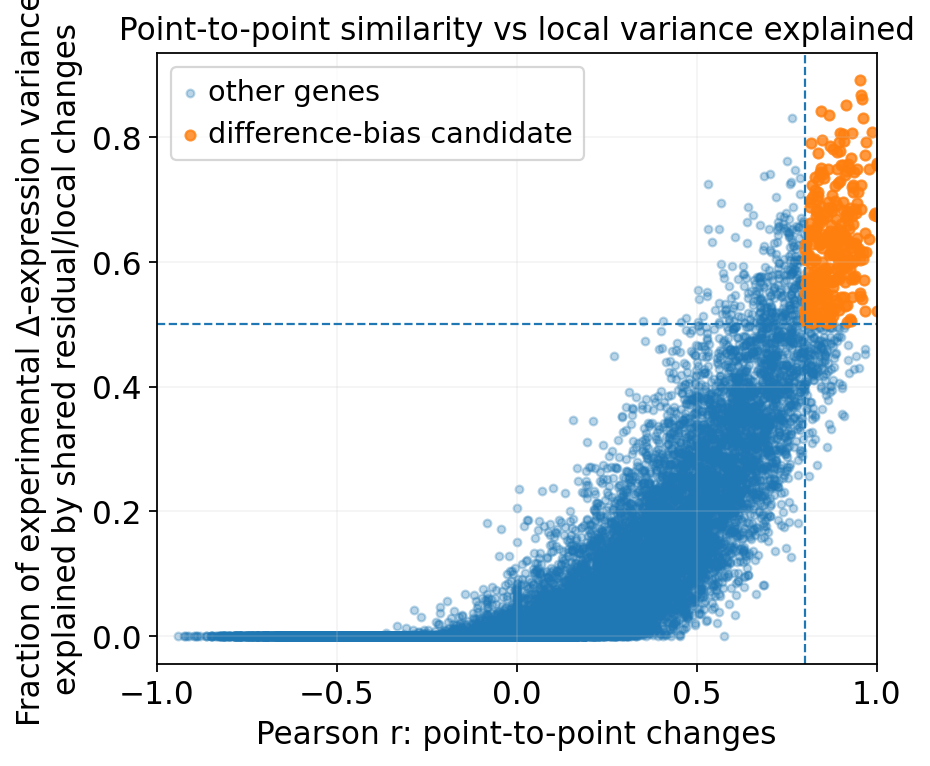

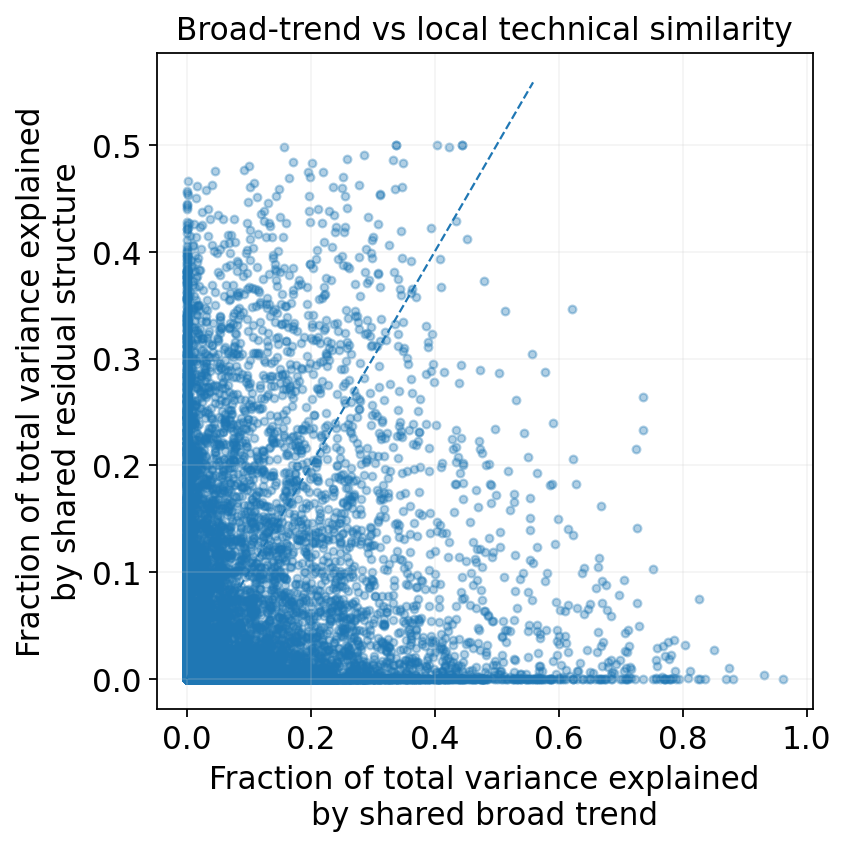

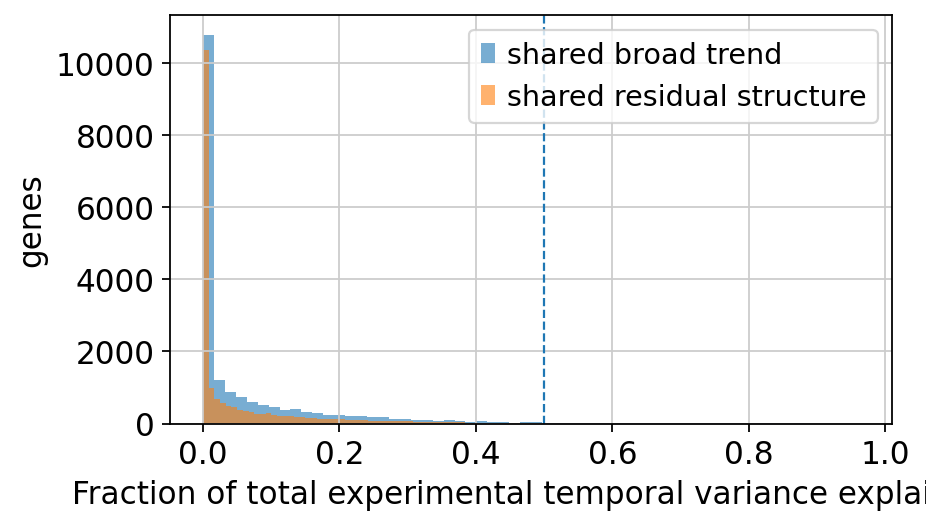

In [24]:
corr = ComputeSmoothCorrelations(
    logcpm,
    logcpm_ref,
    method='spline',
    method_kwargs=dict(s=None, k=3),
    local_r_threshold=0.8,
    local_fraction_threshold=0.5,
)


In [32]:
# Post hoc re-filter corr without recomputing trajectories

local_r_threshold = 0.7
local_fraction_threshold = 0.25

corr["tag_bias_candidate_residual"] = ((corr["pearson_r_residual"] >= local_r_threshold) & (corr["residual_explained_total_fraction"] >= local_fraction_threshold))
corr["tag_bias_candidate_diff"] = ((corr["pearson_r_diff"] >= local_r_threshold) & (corr["diff_residual_explained_fraction"] >= local_fraction_threshold))
# corr["tag_bias_candidate"] = (corr["tag_bias_candidate_residual"] | corr["tag_bias_candidate_diff"])
corr["tag_bias_candidate"] = corr["tag_bias_candidate_residual"]


# Optional: continuous score + re-sort
corr["tag_bias_score"] = corr[["residual_explained_total_fraction", "diff_residual_explained_fraction",]].max(axis=1, skipna=True)
corr = corr.sort_values("max_r_local", ascending=False,)

print("Tag-bias candidates:", int(corr["tag_bias_candidate"].sum()))

corr[
    [
        "pearson_r_residual",
        "residual_explained_total_fraction",
        "pearson_r_diff",
        "diff_residual_explained_fraction",
        "tag_bias_candidate_residual",
        "tag_bias_candidate_diff",
        "tag_bias_candidate",
    ]
].head(20)

Tag-bias candidates: 1025


,pearson_r_residual,residual_explained_total_fraction,pearson_r_diff,diff_residual_explained_fraction,tag_bias_candidate_residual,tag_bias_candidate_diff,tag_bias_candidate
gene,,,,,,,
LINC02029,1.000000,0.499994,1.000000,0.674177,True,True,True
DDX25,1.000000,0.500095,1.000000,0.759077,True,True,True
ENSG00000279881,1.000000,0.500097,1.000000,0.755222,True,True,True
MAP6,1.000000,0.263736,1.000000,0.521177,True,True,True
PAK5,1.000000,0.499994,1.000000,0.674177,True,True,True
LINC01206,1.000000,0.500097,1.000000,0.755222,True,True,True
ENSG00000305226,0.998625,0.498425,0.930697,0.806570,True,True,True
MT-RNR1,0.998284,0.498504,0.994238,0.675906,True,True,True
ENSG00000288845,0.985284,0.485618,0.996473,0.678848,True,True,True


In [34]:
excl_genes = set(corr[corr['tag_bias_candidate'] == True].index.tolist())

In [78]:
'HSPA1B' in excl_genes

False

In [40]:
adata_hvg

View of AnnData object with n_obs × n_vars = 6857 × 2169
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_counts', 'n_genes', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden', 'traj_clusters', 'fate_0', 'fate_1', 'fate_entropy', 'fate_maxprob', 'traj_clusters_mass_ret_cell'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'hvg', 'leiden', 'log1p', 'neighbors', 'ot_graph', 'pca', 'phase_colors', 'sample_colors', 'scrublet', 'terminal_cell_dist_idx_last', 'terminal_fate_probs_traj_fates', 'time_colors', 'time_group_colors', 'traj_clusters', 'traj_clusters_colors', 'traj_clusters_mass_retention_clusters_plotted', 'traj_clusters_mass_retention_o

In [42]:
adata_hvg = adata.copy()

In [43]:
adata_hvg = adata.copy()
adata_hvg = filter_technical_genes(adata_hvg, exclude_genes=excl_genes)
adata_hvg


In [44]:
print('PLAU' in set(adata_hvg.var.index)) # similar shape
print('CD83' in set(adata_hvg.var.index)) # similar shape
print('EGR1' in set(adata_hvg.var.index)) # similar shape
print('IER3' in set(adata_hvg.var.index)) # similar shape

True
True
True
True


In [45]:
# TPs
print('REL' in set(adata_hvg.var.index)) # real, should be included
print('ALAS1' in set(adata_hvg.var.index)) # also real, should be included
print('SLC40A1' in set(adata_hvg.var.index)) # similar shape but a lot noisier
print('TRAF3' in set(adata_hvg.var.index)) # similar shape

# TNs
print('FTH1' in set(adata_hvg.var.index)) # should have high correlation
print('RELA' in set(adata_hvg.var.index)) # similar shape

True
True
True
True
True
True


In [48]:
adata_hvg.write_h5ad('../output/adata_prefiltered.1e4-variant.fixed.h5ad')
pd.Series(list(excl_genes)).to_csv('exclude_time-tag-bias_genes.csv', index=False, )

In [66]:
adata_hvg.var["total_counts"] = np.asarray(
    adata_hvg.layers["counts"].sum(axis=0)
).ravel()

pd.Series(adata_hvg.var.index[adata_hvg.var['total_counts'] < 10]).to_csv('exclude_low-count-genes.k562.csv', index=False)
adata_hvg.var.index[adata_hvg.var['total_counts'] < 10]

/new-stg/home/alex/.tmp/ipykernel_1264968/4141590493.py:1: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata_hvg.var["total_counts"] = np.asarray(


# Prepare input files for TradeSeq

In [72]:
adata_hvg = sc.read_h5ad('../output/adata_prefiltered.1e4-variant.fixed.h5ad')
WriteTradeSeqInputsFromAnnData(adata_hvg, 'sc-K562-1e4_to_tradeSeq.fixed')

(14274, 6857) (6857, 2)
Wrote subset_genes.csv and cell_libsize_full.csv


In [73]:
adata_full = sc.read_h5ad('../output/adata_full.1e4-variant.chk1.h5ad')
WriteTradeSeqInputsFromAnnData(adata_full, 'sc-K562-1e4_to_tradeSeq.fixed', tag='full')

(20036, 6857) (6857, 2)
Wrote subset_genes.csv and cell_libsize_full.csv


In [74]:
# ------------------------------------------------------------
# Soft memberships from per-cell "self-cluster retention"
#   Fix: if retention is NaN (typically terminal timepoint), set to 1.0
# ------------------------------------------------------------
cluster_key = "traj_clusters"
ret_key = "traj_clusters_mass_ret_cell"
basis = "X_ot_umap"   # change to "X_umap" if you prefer
prefix = "softmem"    # obs keys: softmem_*, softmem_entropy, softmem_maxprob, softmem_argmax

assert cluster_key in adata_hvg.obs, f"Missing adata_hvg.obs['{cluster_key}']"
assert ret_key in adata_hvg.obs, f"Missing adata_hvg.obs['{ret_key}']"

lab = adata_hvg.obs[cluster_key].astype(str).to_numpy()
p_self = adata_hvg.obs[ret_key].astype(float).to_numpy()

# NaN -> terminal timepoint (no t+1); treat as perfect self-membership
p_self = np.where(np.isfinite(p_self), p_self, 1.0)
p_self = np.clip(p_self, 0.0, 1.0)
p_other = 1.0 - p_self

# infer the two cluster names (expects exactly 2)
clusts = pd.Categorical(adata_hvg.obs[cluster_key].astype(str)).categories.tolist()
if len(clusts) != 2:
    raise ValueError(f"Expected exactly 2 clusters in {cluster_key}, got {len(clusts)}: {clusts}")
c0, c1 = clusts[0], clusts[1]

# Build p(cluster=c0) and p(cluster=c1)
p_c0 = np.where(lab == c0, p_self, p_other)
p_c1 = np.where(lab == c1, p_self, p_other)

# Store in obs
adata_hvg.obs[f"{prefix}_{c0}"] = p_c0.astype(np.float32)
adata_hvg.obs[f"{prefix}_{c1}"] = p_c1.astype(np.float32)

# summaries
P = np.vstack([p_c0, p_c1]).T
adata_hvg.obs[f"{prefix}_maxprob"] = P.max(axis=1).astype(np.float32)
adata_hvg.obs[f"{prefix}_argmax"] = pd.Categorical(
    np.where(p_c1 > p_c0, c1, c0),
    categories=[c0, c1]
)

eps = 1e-12
ent = -(P * np.log(P + eps)).sum(axis=1) / np.log(2.0)  # entropy (bits), [0,1] for 2 classes
adata_hvg.obs[f"{prefix}_entropy"] = ent.astype(np.float32)

print("NaNs fixed:", int(np.sum(~np.isfinite(adata_hvg.obs[ret_key].to_numpy()))))
print("Created soft memberships:")
print([f"{prefix}_{c0}", f"{prefix}_{c1}", f"{prefix}_entropy", f"{prefix}_maxprob", f"{prefix}_argmax"])

NaNs fixed: 590
Created soft memberships:
['softmem_0', 'softmem_1', 'softmem_entropy', 'softmem_maxprob', 'softmem_argmax']


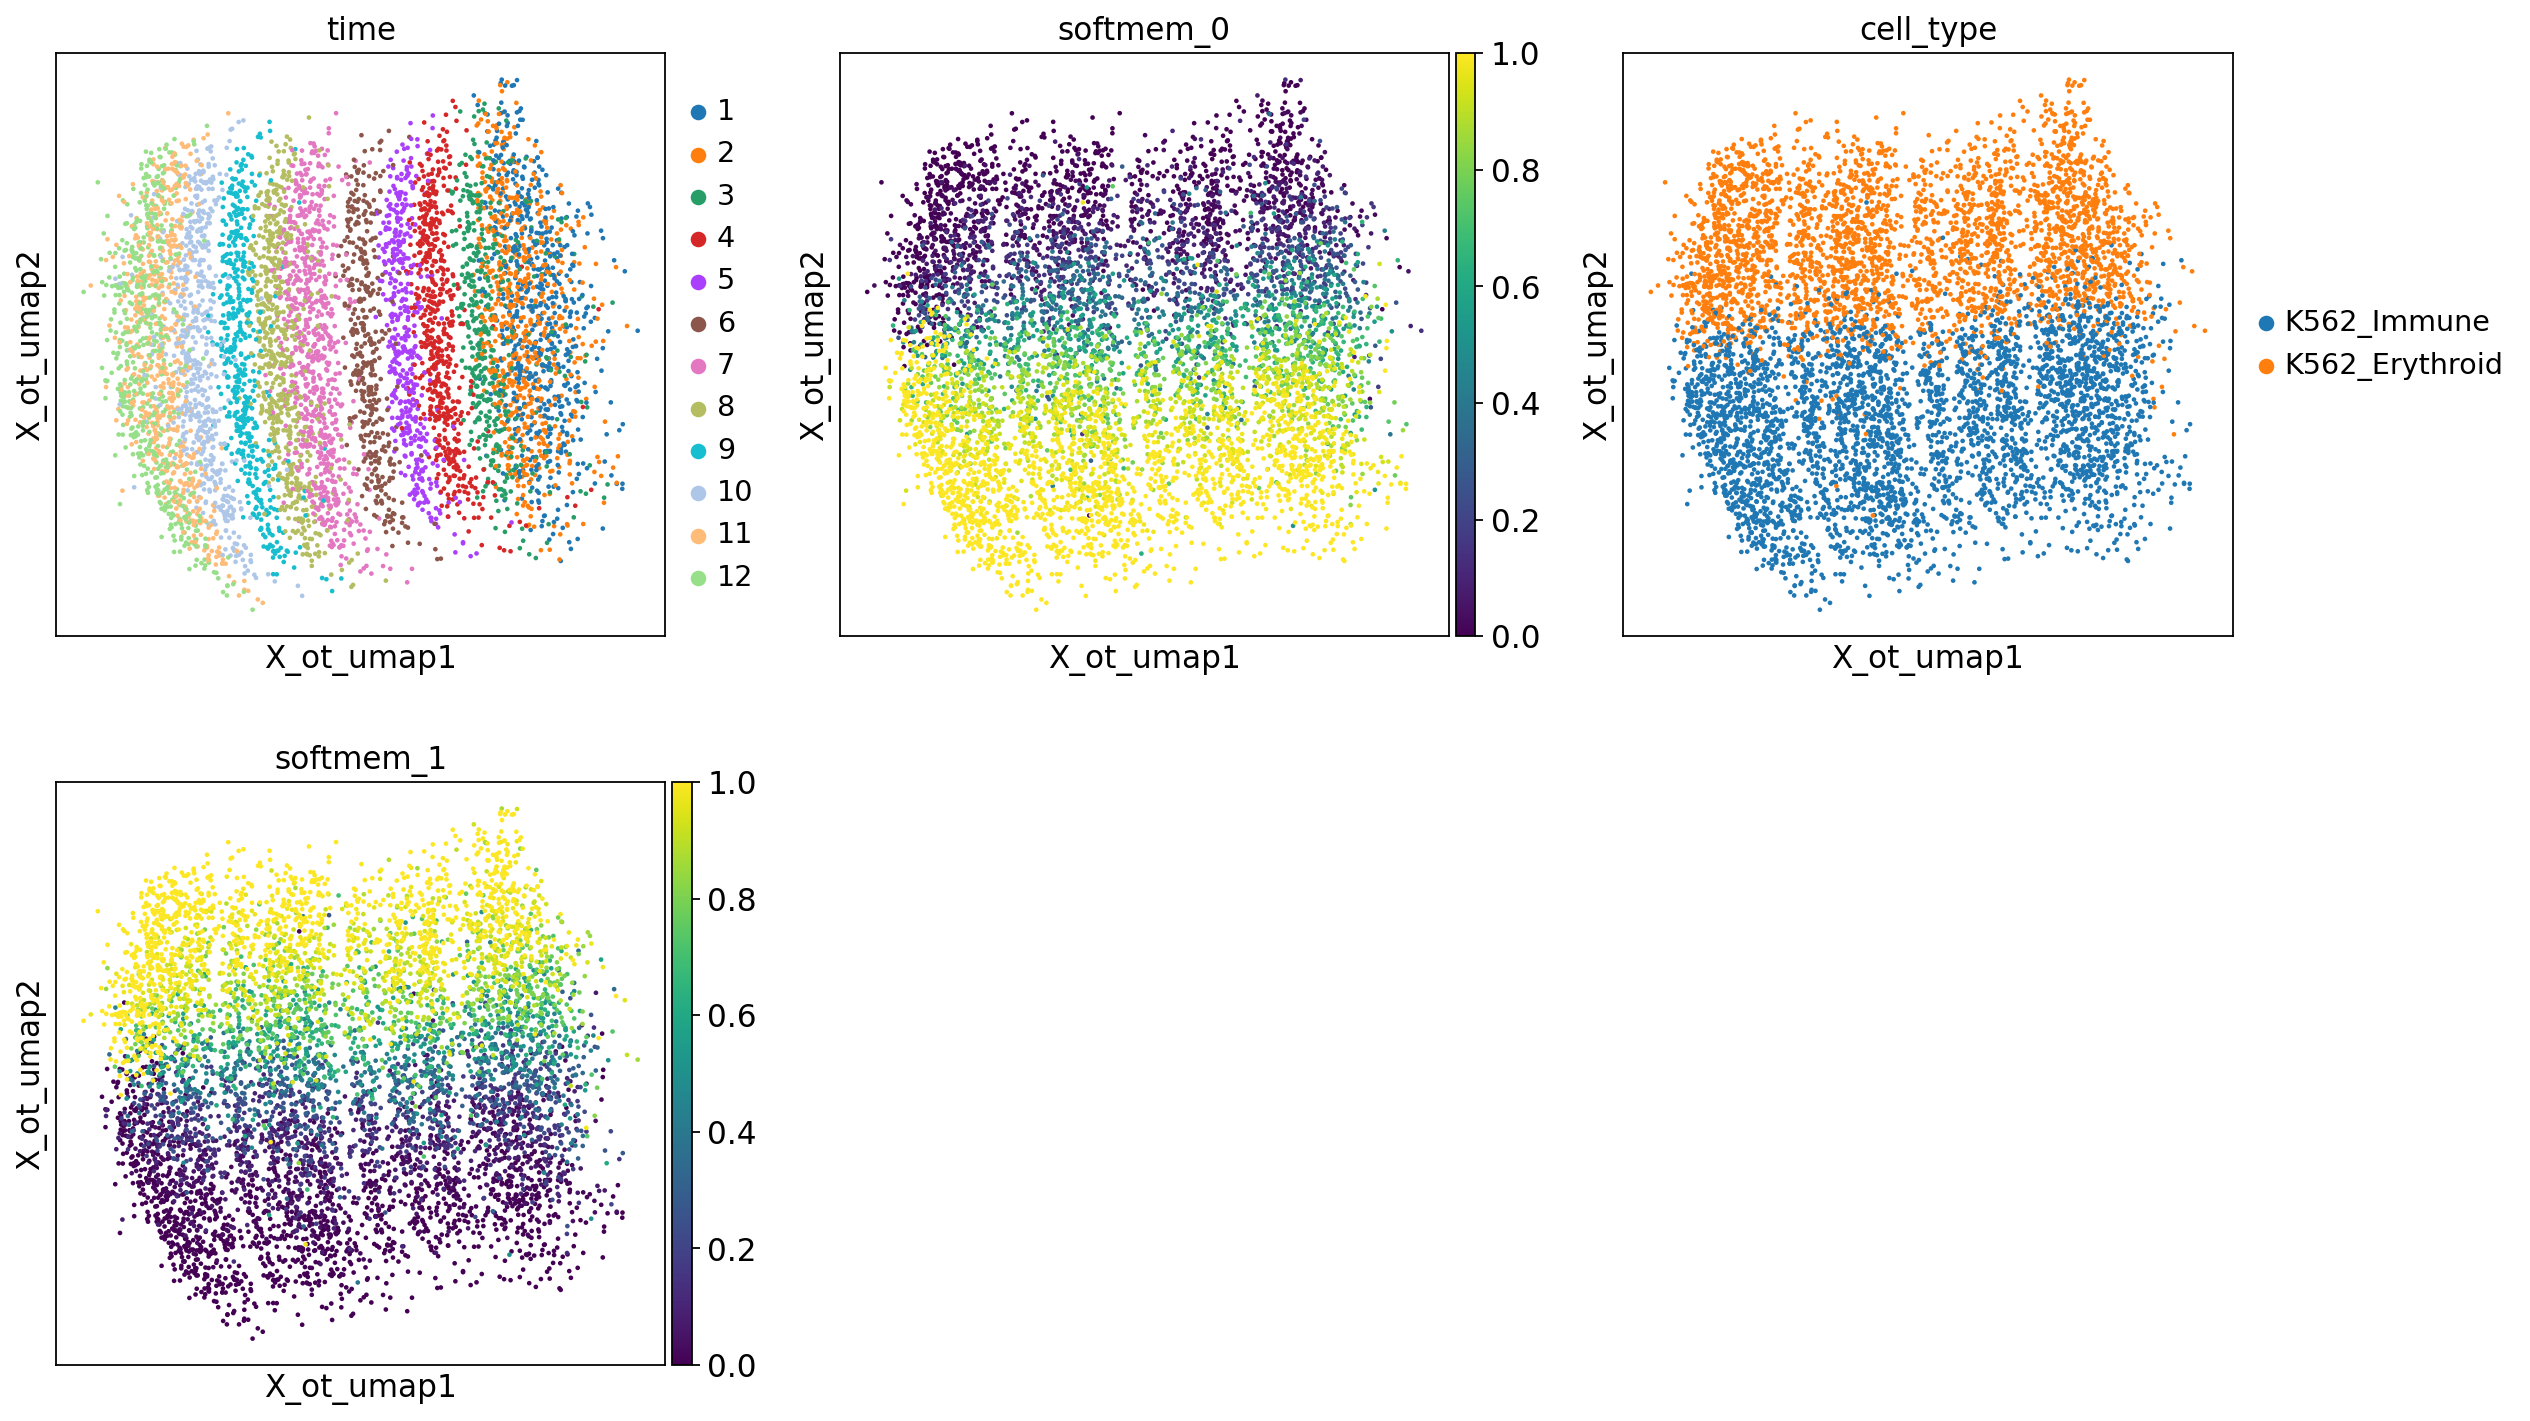

In [75]:
sc.pl.embedding(
    adata_hvg,
    basis='X_ot_umap',
    color=['time', 'softmem_0', 'cell_type', 'softmem_1'],
    ncols=3,
    cmap='viridis'
)

In [76]:
tmp = adata_hvg.copy()

cols = [c for c in ("softmem_0", "softmem_1") if c in tmp.obs.columns]
df = tmp.obs.loc[:, cols].copy()
df.index = df.index.astype(str)  # make sure cell IDs are strings
df.to_csv("../intmd/sc-K562-1e4_to_tradeSeq.fixed/cluster_memberships.retentions.csv", index=True, index_label="cell_id")